# Are short-horizon crypto prediction markets calibrated? Data, splits and baseline

This notebook covers steps 2 to 5 of the project workflow for the idea in
[`research/idea_prediction_market_calibration.md`](../../research/idea_prediction_market_calibration.md):

1. **Data.** Polymarket's five-minute "Bitcoin Up or Down" markets with per-second quotes, and Binance spot prices per second.
2. **Preprocessing and split.** What the outcome labels really are, how to align market and spot data in time, chronological train / dev / test split, leakage checks.
3. **Baseline.** Task, metrics, protocol, and the market's own price as the fixed baseline.
4. **Method fit.** Whether recalibration or models built on spot data forecast better than the market.

The literature review is in [`research/literature/literature_review_prediction_markets.md`](../../research/literature/literature_review_prediction_markets.md)
and the conclusions are in [`research/prediction_market_writeup.md`](../../research/prediction_market_writeup.md).

Reusable code lives in `src/scripts/prediction_markets.py`, with tests in `tests/test_prediction_markets.py`.
The notebook runs in about a minute once the data is in place.

In [1]:
import sys
import warnings
from datetime import timedelta

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression

sys.path.append("../scripts")
import prediction_markets as pm
import regimes as rg                      # for mean_diff_se: a standard error that allows for autocorrelation

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220, "display.max_columns", 30, "display.float_format", "{:,.4f}".format)

DECISION_TIMES = [0, 60, 120, 240]        # seconds into the five minutes at which a forecast is made
PRIMARY = 60                              # the primary decision time, fixed before looking at results
FIRST_DEV, FIRST_TEST = "2026-04-29", "2026-05-09"

# Chart style: one fixed colour per series, thin lines, quiet grid.
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 90, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "xtick.color": MUTED, "ytick.color": MUTED,
    "lines.linewidth": 1.4, "legend.frameon": False, "font.size": 9.5,
})

## 1. Data

**The markets.** Polymarket lists a new market every five minutes: will Bitcoin be higher or lower at the
end of the five minutes than at their start? Two shares trade, "Up" and "Down", each paying 1 dollar if it
is right. The price of the Up share is the market's probability of an up move.

**Sources.**

- **Market data:** the public dataset
  [`kachoio/polymarket-5-minute-crypto-up-down-markets`](https://huggingface.co/datasets/kachoio/polymarket-5-minute-crypto-up-down-markets)
  on Hugging Face (licence CC0). Its author recorded the order book once per second. The BTC files were
  already in `data/polymarket_5m_kachoio/`; `pm.download_markets()` fetches them if they are missing.
- **Spot prices:** Binance BTC/USDT one-second candles from [data.binance.vision](https://data.binance.vision),
  downloaded for this study by `pm.download_spot_seconds()` (48 MB). One-minute candles were already in the
  repository, but a forecast made 60 seconds into a market needs to know the price at exactly that second.

In [2]:
pm.download_markets()
markets, ticks = pm.load_markets(), pm.load_ticks()
first_day, last_day = markets["market_start"].min().date(), markets["market_end"].max().date()
if not pm.SPOT_FILE.exists():
    pm.download_spot_seconds(first_day - timedelta(days=1), last_day)
spot = pm.load_spot_seconds()

start = markets["market_start"].map(lambda ts: int(ts.timestamp())).to_numpy()
gaps = np.diff(start)
both_mids = (ticks["bu"] + ticks["au"]) / 2 + (ticks["bd"] + ticks["ad"]) / 2
spread = ticks["au"] - ticks["bu"]
pd.Series({
    "markets": len(markets), "first market": str(markets["market_start"].min()), "last market": str(markets["market_start"].max()),
    "days covered": (markets["market_start"].max() - markets["market_start"].min()).days + 1,
    "markets that start 5 minutes after the previous one %": 100 * (gaps == 300).mean(),
    "longest gap between markets (minutes)": gaps.max() / 60,
    "markets with all 300 per-second quotes %": 100 * (markets["n_ticks"] == 300).mean(),
    "quote rows": len(ticks), "missing bid or ask": int(ticks[["bu", "au", "bd", "ad"]].isna().sum().sum()),
    "rows where bid >= ask": int((ticks["bu"] >= ticks["au"]).sum()),
    "median spread of the Up share (dollars)": spread.median(), "99th percentile of the spread": spread.quantile(0.99),
    "Up mid + Down mid, mean": both_mids.mean(), "Up mid + Down mid, standard deviation": both_mids.std(),
    "spot seconds": len(spot), "spot seconds without a price": int(spot.isna().sum()),
    "markets with a recorded outcome %": 100 * markets["outcome"].notna().mean(),
}, name="value").to_frame()

,value
markets,15682
first market,2026-03-24 22:10:00+00:00
last market,2026-05-18 10:30:00+00:00
days covered,55
markets that start 5 minutes after the previous one %,99.9745
longest gap between markets (minutes),80.0000
markets with all 300 per-second quotes %,99.9809
quote rows,4704518
missing bid or ask,0
rows where bid >= ask,162


**Validation.**

- **Coverage is nearly complete:** eight weeks (24 March to 18 May 2026), with all but four markets
  following the previous one directly. The longest gap is 80 minutes on 18 April, a recording outage documented by the dataset's author.
- **The quotes are clean:** no missing bids or asks, practically no crossed quotes, a typical spread of one
  cent, and the Up and Down mid prices add up to 1 almost exactly.
- **Spot prices** cover every second of the period.
- **About 9% of the markets have no recorded outcome.** That needs a closer look.

## 2. What the outcome labels really are

The idea file called the labels "exact". They are not. The dataset's documentation states that `outcome` is
**inferred from the last recorded quote**, one second before the market ends, not read from the on-chain
resolution, and that it is empty when that quote was not decisive.

In [3]:
quotes = pm.quotes_at(markets, ticks, DECISION_TIMES + [299])
markets = pm.add_targets(markets, quotes["mid_299"]).join(quotes)
markets["spot_start"] = pm.spot_before(spot, start)
markets["spot_end"] = pm.spot_before(spot, start + pm.MARKET_SECONDS)
markets["spot_move_bps"] = 1e4 * np.log(markets["spot_end"] / markets["spot_start"])
markets["spot_up"] = (markets["spot_end"] >= markets["spot_start"]).astype(float)

print("Up share's bid in the market's last second, by recorded outcome:")
display(markets.groupby(markets["outcome"].fillna("not recorded"))["bid_299"].describe()[["count", "min", "50%", "max"]])

labeled = markets["hard"].notna()
size = markets["spot_move_bps"].abs()
rows = {}
for low, high, name in [(0, 1, "under 1"), (1, 2, "1 to 2"), (2, 5, "2 to 5"), (5, 10, "5 to 10"), (10, np.inf, "over 10")]:
    inside = (size >= low) & (size < high)
    rows[name] = {"markets": int(inside.sum()), "without a recorded outcome %": 100 * (inside & ~labeled).sum() / inside.sum(),
                  "recorded outcome agrees with Binance %": 100 * (markets.loc[inside & labeled, "spot_up"] == markets.loc[inside & labeled, "hard"]).mean()}
print(f"Recorded outcome agrees with the direction of the Binance price: {100 * (markets.loc[labeled, 'spot_up'] == markets.loc[labeled, 'hard']).mean():.1f}% of {int(labeled.sum()):,} markets")
print("By size of the five-minute move on Binance (basis points):")
display(pd.DataFrame(rows).T.rename_axis("absolute move"))
undecided = markets[~labeled]
print(f"Markets without a recorded outcome: {len(undecided):,}; their last mid price ranges from {undecided['mid_299'].min():.2f} to {undecided['mid_299'].max():.2f}")
print(f"Among them, Binance went up in {100 * undecided.loc[undecided['mid_299'] > 0.5, 'spot_up'].mean():.0f}% of those with a last mid above 0.5 and in {100 * undecided.loc[undecided['mid_299'] < 0.5, 'spot_up'].mean():.0f}% of those below")

Up share's bid in the market's last second, by recorded outcome:


,count,min,50%,max
outcome,,,,
Down,"7,049.0000",0.0000,0.0000,0.0800
Up,"7,177.0000",0.9100,0.9900,0.9990
not recorded,"1,456.0000",0.0000,0.4700,0.9000


Recorded outcome agrees with the direction of the Binance price: 98.6% of 14,226 markets
By size of the five-minute move on Binance (basis points):


,markets,without a recorded outcome %,recorded outcome agrees with Binance %
absolute move,,,
under 1,"1,833.0000",42.6077,84.0304
1 to 2,"1,988.0000",18.8632,98.5121
2 to 5,"4,080.0000",5.1716,99.8191
5 to 10,"3,983.0000",1.3558,99.9491
over 10,"3,798.0000",0.9215,99.9734


Markets without a recorded outcome: 1,456; their last mid price ranges from 0.06 to 0.94
Among them, Binance went up in 70% of those with a last mid above 0.5 and in 28% of those below


**The labels are the market's own final opinion, and the missing ones are the close calls.**

- A market is labeled Up when the Up share's bid was at least 0.91 in the last second, Down when it was at
  most 0.08, and left empty in between.
- The empty ones are not random. Among markets in which Bitcoin moved less than one basis point, more than
  40% have no label; among those with a move above ten basis points, under 1%.
- **Dropping the unlabeled markets would remove exactly the undecided cases** and distort any calibration
  measurement.
- **The Binance price cannot replace the label.** The recorded outcomes agree with the direction of the
  Binance price in 98.6% of markets, but only in 84% when the move is under one basis point. The markets
  resolve on a different price feed, and for close calls the two disagree often.
- The true resolutions could not be obtained: Polymarket's API is not reachable from this machine, and an
  attempt to read them from the Polygon blockchain did not find the events.

**Decision: soft labels.** A labeled market gets target 1 or 0. An unlabeled one gets the Up share's mid
price in its last second as its target: one second before the end, that price is the best available
estimate of the outcome. Forecasts are scored against this target, which keeps every market in the sample.
Section 6 checks how much the conclusions depend on this choice.

## 3. Descriptive statistics

,markets with a quote,mean mid,standard deviation of mid,share of mids between 0.4 and 0.6 %,median spread
seconds into the market,,,,,
0 s,"15,679.0000",0.5023,0.0481,94.0378,0.0100
60 s,"15,681.0000",0.5035,0.1768,39.8482,0.0100
120 s,"15,682.0000",0.5033,0.2465,26.1510,0.0100
240 s,"15,682.0000",0.5013,0.3665,12.0074,0.0100
299 s,"15,682.0000",0.5038,0.4765,1.8875,0.0100


share of Up: recorded outcomes 50.45%, soft targets 50.39%, Binance direction 50.20%
five-minute move of the Binance price: standard deviation 11.4 bps, median absolute move 4.9 bps


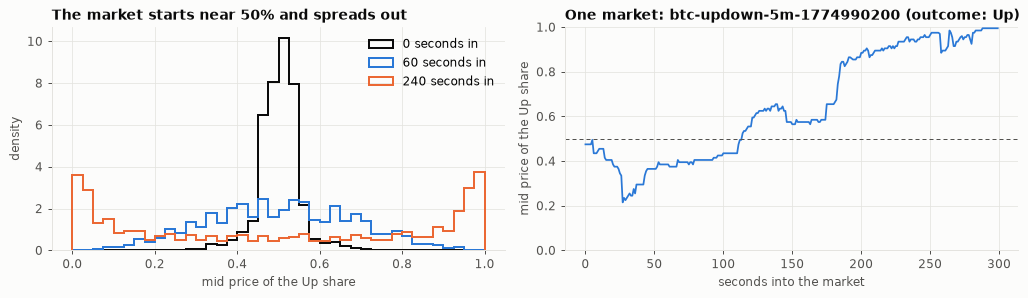

In [4]:
markets["split"] = pm.chrono_split(markets, FIRST_DEV, FIRST_TEST)
describe = pd.DataFrame({
    f"{s} s": {"markets with a quote": int(markets[f"mid_{s}"].notna().sum()), "mean mid": markets[f"mid_{s}"].mean(), "standard deviation of mid": markets[f"mid_{s}"].std(),
               "share of mids between 0.4 and 0.6 %": 100 * markets[f"mid_{s}"].between(0.4, 0.6).mean(), "median spread": markets[f"spread_{s}"].median()}
    for s in DECISION_TIMES + [299]}).T.rename_axis("seconds into the market")
display(describe)
print(f"share of Up: recorded outcomes {100 * markets['hard'].mean():.2f}%, soft targets {100 * markets['target'].mean():.2f}%, Binance direction {100 * markets['spot_up'].mean():.2f}%")
print(f"five-minute move of the Binance price: standard deviation {markets['spot_move_bps'].std():.1f} bps, median absolute move {markets['spot_move_bps'].abs().median():.1f} bps")

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.4))
bins = np.linspace(0, 1, 41)
for s, color in [(0, INK), (60, BLUE), (240, ORANGE)]:
    axes[0].hist(markets[f"mid_{s}"].dropna(), bins=bins, histtype="step", color=color, linewidth=1.6, label=f"{s} seconds in", density=True)
axes[0].set_xlabel("mid price of the Up share"); axes[0].set_ylabel("density"); axes[0].set_title("The market starts near 50% and spreads out"); axes[0].legend()
example = markets.index[markets["market_start"] == markets["market_start"].iloc[2000]][0]
one = ticks[ticks["condition_id"] == example].sort_values("t")
axes[1].plot(one["t"] - one["t"].min(), (one["bu"] + one["au"]) / 2, color=BLUE)
axes[1].axhline(0.5, color=MUTED, linewidth=0.8, linestyle=(0, (4, 3)))
axes[1].set_ylim(0, 1); axes[1].set_xlabel("seconds into the market"); axes[1].set_ylabel("mid price of the Up share")
axes[1].set_title(f"One market: {markets.loc[example, 'slug']} (outcome: {markets.loc[example, 'outcome']})")
fig.tight_layout(); plt.show()

**Sizes.** 15,682 markets, one after the other without overlap, each with a quote for every second. Near a
price of 0.5, one standard error of an observed frequency over the whole sample is 0.4 percentage points.
That is enough to detect a miscalibration of one to two points overall, and not enough for fine detail
inside a ten-day test period (about 2,700 markets, 1 percentage point).

**The outcome is balanced:** Up happens 50.4% of the time.

**The market's information grows quickly.** At the open almost every market is priced between 0.4 and 0.6.
One minute in, the prices have spread out; four minutes in, most markets are close to decided.

### 3.1 Feature set and labels

| | Choice | Why |
| --- | --- | --- |
| **Decision times** | 0, 60, 120 and 240 seconds into the market. **60 seconds is the primary one**, fixed before looking at results. | Each moment is its own forecasting problem. Fixing one in advance keeps the best of several from being reported as the finding. |
| **Baseline forecast** | The Up share's mid price at the decision time | The market's own probability. |
| **Spot features** | The move of the Binance price since the market opened, divided by recent volatility and the square root of the time left; the previous five-minute move; the last hour's move; the bid-ask spread | What a model without access to the market price would use: how far ahead "up" is, relative to how much the price can still move. |
| **Label** | 1 for Up, 0 for Down, and the last mid price where the outcome is not recorded (section 2) | |

## 4. Exploratory analysis and preprocessing

### 4.1 Does the price open at 50%, and should it?

The complexity study found that the direction of an hourly return tends to reverse. If the same holds at
five minutes, a market that opens at exactly 50% would be slightly wrong.

In [5]:
consecutive = np.r_[False, gaps == 300]
previous_target = np.where(consecutive, np.r_[np.nan, markets["target"].to_numpy()[:-1]], np.nan)
spot_up = markets["spot_up"].to_numpy()
repeat = (spot_up[1:] == spot_up[:-1])[gaps == 300]
print(f"Binance: a five-minute move has the same direction as the previous one {100 * repeat.mean():.2f}% of the time (n = {len(repeat):,}, standard error {100 * np.sqrt(0.25 / len(repeat)):.2f})")

rows = {}
for name, mask in [("the previous market went Up", previous_target > 0.5), ("the previous market went Down", previous_target < 0.5)]:
    rows[name] = {"markets": int(mask.sum()), "mean opening price": markets.loc[mask, "mid_0"].mean(),
                  "share that went Up": markets.loc[mask, "target"].mean(), "standard error": np.sqrt(0.25 / mask.sum())}
display(pd.DataFrame(rows).T)
at_open = markets["mid_0"].notna()
cost = pm.log_loss(markets.loc[at_open, "target"], markets.loc[at_open, "mid_0"]) - 1.0
difference, error = rg.mean_diff_se(cost, np.zeros(len(cost)), lags=12)
print(f"Opening price against a flat 50%: {difference:+.4f} bits per market (standard error {error:.4f}); negative means the opening price is the better forecast")

Binance: a five-minute move has the same direction as the previous one 49.00% of the time (n = 15,677, standard error 0.40)


,markets,mean opening price,share that went Up,standard error
the previous market went Up,"7,921.0000",0.4963,0.4942,0.0056
the previous market went Down,"7,753.0000",0.5086,0.5137,0.0057


Opening price against a flat 50%: -0.0081 bits per market (standard error 0.0011); negative means the opening price is the better forecast


**The reversal exists at five minutes too, and the market prices it in.**

- On Binance, a five-minute move repeats the direction of the previous one a little less than half the time.
- After an Up market the next one opens slightly below 50%, after a Down market slightly above, and the
  outcomes that follow match those opening prices within the noise.
- The opening price is a better forecast than a flat 50%, by a small but statistically clear margin.

So the question from the idea file has an answer: the effect found at hourly bars is present here, and it
is not an inefficiency of this market.

### 4.2 Preprocessing decisions

| Issue found in the data | Decision |
| --- | --- |
| Outcomes are inferred, and missing for close calls | Soft labels (section 2). Sensitivity to this choice is reported. |
| A spot candle of second *s* is complete only at *s* + 1 | A forecast at time *t* uses spot prices up to second *t* - 1 only (`pm.spot_before`, tested). |
| The market quote at second *t* | Used as recorded: it was resting in the book at *t*. |
| Markets resolve on another price feed than Binance | Binance prices are used as features only, never as labels. |
| Volatility changes through the day and from day to day | The move since the open is divided by the volatility of the preceding hour. |
| Forecasts of exactly 0 or 1 | Clipped to 0.0001 and 0.9999 before the log loss. |
| A few markets lack a quote at second 0 | Left out at that decision time only. |
| Neighbouring markets share volatility and news | Standard errors allow for autocorrelation (12 lags, one hour). |

In [6]:
def features(tau):
    # Everything a forecaster knows `tau` seconds into each market. Spot prices strictly before that moment.
    now = start + tau
    f = pd.DataFrame(index=markets.index)
    f["market"] = markets[f"mid_{tau}"]
    f["logit_market"] = pm.logit(f["market"])
    f["spread"] = markets[f"spread_{tau}"]
    f["volatility"] = pm.trailing_volatility(spot, now, window=3600, step=60)
    move = np.log(pm.spot_before(spot, now) / markets["spot_start"].to_numpy()) if tau > 0 else np.zeros(len(markets))
    f["z"] = move / (f["volatility"] * np.sqrt(pm.MARKET_SECONDS - tau))            # how far ahead, in units of what can still happen
    f["previous_z"] = np.log(markets["spot_start"].to_numpy() / pm.spot_before(spot, start - 300)) / (f["volatility"] * np.sqrt(300))
    f["hour_z"] = np.log(markets["spot_start"].to_numpy() / pm.spot_before(spot, start - 3600)) / (f["volatility"] * np.sqrt(3600))
    return f

feature_sets = {tau: features(tau) for tau in DECISION_TIMES}
split_table = markets.groupby("split").agg(
    first=("market_start", "min"), last=("market_start", "max"), markets=("target", "size"),
    without_recorded_outcome=("hard", lambda s: 100 * s.isna().mean()), share_up=("target", lambda s: 100 * s.mean()),
    spot_volatility_bps=("spot_move_bps", "std")).loc[["train", "dev", "test"]]
split_table["days"] = (split_table["last"] - split_table["first"]).dt.days + 1

# Save the modelling table (data/ is ignored by git).
out_dir = pm.DATA_DIR / "processed" / "prediction_markets"
out_dir.mkdir(parents=True, exist_ok=True)
markets.join(feature_sets[PRIMARY].add_suffix(f"_at_{PRIMARY}")).to_parquet(out_dir / "btc_5m_markets.parquet")
split_table

,first,last,markets,without_recorded_outcome,share_up,spot_volatility_bps,days
split,,,,,,,
train,2026-03-24 22:10:00+00:00,2026-04-28 23:55:00+00:00,10083,8.5292,50.5794,12.3178,36
dev,2026-04-29 00:00:00+00:00,2026-05-08 23:55:00+00:00,2880,13.7847,50.3611,10.1336,10
test,2026-05-09 00:00:00+00:00,2026-05-18 10:30:00+00:00,2719,7.3189,49.7466,8.8321,10


### 4.3 The split

**By time:** train is the first 36 days (to 28 April), dev the next ten (29 April to 8 May), test the last
ten (9 to 18 May). Markets are never shuffled.

- Dev contains 30 April and 1 May, two days on which an unusually large share of markets has no recorded
  outcome. The soft labels keep those markets in.
- Volatility differs somewhat between the periods, which is why the spot features are scaled by it.

### 4.4 Leakage checklist

| Risk | How it is handled |
| --- | --- |
| A feature uses information from after the decision time | Spot features use prices strictly before it (`pm.spot_before` and `pm.trailing_volatility`, both tested by changing future prices). |
| The label is built from the same market's later quotes | True, and unavoidable with this dataset: the label is the market's own price one second before the end. It is 240 seconds after the primary decision time. A forecast cannot see it, but the "truth" is partly the market's opinion (see the limitations in the write-up). |
| Random split mixes neighbouring markets | Split by date only. |
| Recalibration or model fitted on the period it is scored on | Fitted on train, scored on dev. |
| Choosing the best decision time after the fact | 60 seconds was fixed as primary before any score was computed. |
| Tuning on test | Candidate models are scored on dev only. Test is used for the market price and the no-information reference. |
| Dropping unlabeled markets selects on the outcome | Not dropped; soft labels. |

## 5. Baseline

### 5.1 Task, metrics and protocol

**Task.** At a fixed number of seconds into each market, give the probability that it resolves Up.

**Metrics.**

| Metric | Definition | Why |
| --- | --- | --- |
| **Log loss** (main), in bits per market | $-\log_2$ of the probability given to what happened | A proper scoring rule: only the true probability minimizes it. A flat 50% costs exactly 1 bit, so the saving below 1 is the information in the forecast. The market price is scored exactly like a model. |
| **Brier score** | squared error of the probability | Also proper, less sensitive to forecasts near 0 or 1. |
| **Reliability** | within bins of the forecast, the observed frequency minus the mean forecast | This is calibration itself. The Brier score splits into a reliability part (miscalibration, 0 is best) and a resolution part (how much the forecast separates outcomes). |
| **Paired differences with standard errors** | mean difference in log loss between two forecasts, with a standard error that allows for autocorrelation | Whether one forecast beats another by more than noise. |

**Protocol.** Fit anything that needs fitting on train; score dev, then test. No refitting.

**Baselines.**

| Forecast | |
| --- | --- |
| Always 50% | No information. Costs 1 bit. |
| **The market's mid price (the fixed baseline)** | Nothing fitted. The question of the study is whether anything beats it. |

In [7]:
def score_market(tau, split):
    rows = (markets["split"] == split) & markets[f"mid_{tau}"].notna()
    target, forecast = markets.loc[rows, "target"].to_numpy(), markets.loc[rows, f"mid_{tau}"].to_numpy()
    loss = pm.log_loss(target, forecast)
    gain, error = rg.mean_diff_se(np.ones(len(loss)), loss, lags=12)        # bits saved against a flat 50%
    parts = pm.brier_decomposition(forecast, target)
    return {"markets": int(rows.sum()), "log loss (bits)": loss.mean(), "bits saved vs. 50%": gain, "standard error": error,
            "Brier score": parts["brier"], "reliability (miscalibration)": parts["reliability"], "resolution": parts["resolution"]}

baseline_table = pd.DataFrame({(split, f"{tau} s"): score_market(tau, split) for split in ["dev", "test"] for tau in DECISION_TIMES}).T
baseline_table

markets  log loss (bits)  bits saved vs. 50%  standard error  Brier score  reliability (miscalibration)  resolution
dev  0 s   2,879.0000           0.9934              0.0066          0.0024       0.2229                        0.0006      0.0024
     60 s  2,880.0000           0.9027              0.0973          0.0085       0.1939                        0.0002      0.0304
     120 s 2,880.0000           0.7798              0.2202          0.0114       0.1575                        0.0005      0.0677
     240 s 2,880.0000           0.5334              0.4666          0.0139       0.0939                        0.0002      0.1309
test 0 s   2,719.0000           0.9881              0.0119          0.0032       0.2335                        0.0005      0.0041
     60 s  2,719.0000           0.8775              0.1225          0.0103       0.1980                        0.0008      0.0399
     120 s 2,719.0000           0.7759              0.2241          0.0123       0.1690                        0.0005      0.0677
     240 s 2,719.0000           0.4852              0.5148          0.0163       0.0942                        0.0001      0.1435

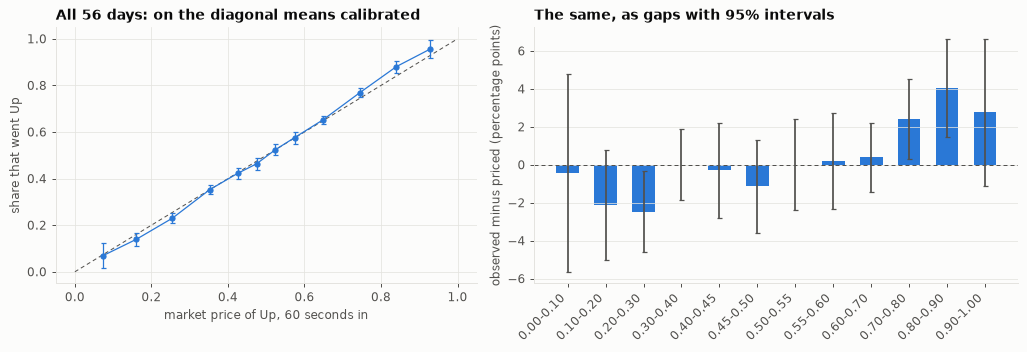

,bin,n,mean_forecast,observed,gap,se
0,0.00-0.10,91,0.0735,0.0692,-0.0042,0.0266
1,0.10-0.20,553,0.1604,0.1392,-0.0212,0.0147
2,0.20-0.30,1497,0.2548,0.2301,-0.0248,0.0109
3,0.30-0.40,2454,0.3522,0.3524,0.0001,0.0096
4,0.40-0.45,1488,0.4252,0.4222,-0.0030,0.0128
5,0.45-0.50,1591,0.4747,0.4633,-0.0114,0.0125
6,0.50-0.55,1692,0.5237,0.5238,0.0001,0.0121
7,0.55-0.60,1469,0.5740,0.5757,0.0018,0.0129
8,0.60-0.70,2594,0.6479,0.6518,0.0039,0.0094
9,0.70-0.80,1528,0.7451,0.7694,0.0243,0.0108


In [8]:
edges = [0, 0.1, 0.2, 0.3, 0.4, 0.45, 0.5, 0.55, 0.6, 0.7, 0.8, 0.9, 1]
has_quote = markets[f"mid_{PRIMARY}"].notna()
reliability = pm.reliability_table(markets.loc[has_quote, f"mid_{PRIMARY}"], markets.loc[has_quote, "target"], edges)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4), gridspec_kw={"width_ratios": [1, 1.15]})
axes[0].plot([0, 1], [0, 1], color=MUTED, linewidth=0.8, linestyle=(0, (4, 3)))
axes[0].errorbar(reliability["mean_forecast"], reliability["observed"], yerr=1.96 * reliability["se"], color=BLUE, marker="o", markersize=4, linewidth=1.0, capsize=2)
axes[0].set_xlabel(f"market price of Up, {PRIMARY} seconds in"); axes[0].set_ylabel("share that went Up")
axes[0].set_title("All 56 days: on the diagonal means calibrated")
axes[1].axhline(0, color=MUTED, linewidth=0.8, linestyle=(0, (4, 3)))
axes[1].bar(np.arange(len(reliability)), 100 * reliability["gap"], yerr=196 * reliability["se"], color=BLUE, width=0.6, ecolor=MUTED, capsize=2)
axes[1].set_xticks(np.arange(len(reliability))); axes[1].set_xticklabels(reliability["bin"], rotation=45, ha="right")
axes[1].set_ylabel("observed minus priced (percentage points)"); axes[1].set_title("The same, as gaps with 95% intervals"); axes[1].grid(axis="x", visible=False)
fig.tight_layout(); plt.show()
reliability

In [9]:
# The one visible pattern: are strong favourites slightly underpriced? Checked in each period separately.
def favourites(split, tau=PRIMARY, low=0.8):
    g = markets[(markets["split"] == split) & markets[f"mid_{tau}"].notna()]
    mid = g[f"mid_{tau}"].to_numpy()
    price = np.where(mid >= 0.5, mid, 1 - mid)                              # price of whichever side is ahead
    won = np.where(mid >= 0.5, g["target"], 1 - g["target"])
    paid = np.where(mid >= 0.5, g[f"ask_{tau}"], 1 - g[f"bid_{tau}"])        # what buying that side costs
    keep = price >= low
    return {"markets": int(keep.sum()), "mean price": price[keep].mean(), "share that won": won[keep].mean(),
            "gap (points)": 100 * (won[keep] - price[keep]).mean(), "standard error (points)": 100 * won[keep].std() / np.sqrt(keep.sum()),
            "profit per share after the spread (cents)": 100 * (won[keep] - paid[keep]).mean()}

print(f"Markets in which one side is priced at 0.80 or more, {PRIMARY} seconds in:")
pd.DataFrame({split: favourites(split) for split in ["train", "dev", "test"]}).T

Markets in which one side is priced at 0.80 or more, 60 seconds in:


,markets,mean price,share that won,gap (points),standard error (points),profit per share after the spread (cents)
train,843.0000,0.8529,0.8837,3.0854,1.0610,2.5320
dev,240.0000,0.8508,0.8846,3.3813,1.9700,2.8188
test,294.0000,0.8520,0.8747,2.2772,1.8674,1.6156


### 5.2 How the baseline performs

- **The market is well calibrated.** At every decision time and in both periods the miscalibration part of
  the Brier score is a fraction of a percent of the score. In the reliability chart almost every point is on
  the diagonal within its interval.
- **It is informative from the first second.** Even the opening price beats a flat 50% by a little; one
  minute in, the market saves about a tenth of a bit per market; four minutes in, almost half a bit.
- **One pattern stands out: prices are slightly compressed towards 50%.** Sixty seconds in, sides priced
  above 0.8 win about three points more often than their price says, and sides priced below 0.2 lose about
  as much more often. This is the "favourite-longshot bias" known from betting markets.
- **The pattern has the same sign in train, dev and test,** but it is individually significant only in
  train, and several bins and two decision times were looked at before it was singled out. Buying strong
  favourites at the ask would have earned 1.6 to 2.8 cents per share in each period, before any fees.
  This is a lead, not a result.

## 6. Method fit: can anything beat the market?

Candidates, all fitted on train and scored on dev:

- **Recalibration:** a monotone correction of the market price (isotonic regression), and a one-parameter
  stretch of its log odds (logistic regression). If the compression of section 5 is real and stable, these
  win.
- **Structural model:** the probability of finishing Up from the spot move so far, scaled by volatility and
  time left. No market price.
- **Market plus spot:** logistic regression on the market's log odds and the spot features. If the market
  misses something that is in the spot price, this wins.
- **Gradient boosting** on the same inputs.

In [10]:
def candidates(tau):
    f = feature_sets[tau]
    usable = f.notna().all(axis=1)
    fit_rows = usable & (markets["split"] == "train") & markets["hard"].notna()      # fit on recorded outcomes only
    dev_rows = usable & (markets["split"] == "dev")
    y_fit, y_dev = markets.loc[fit_rows, "hard"].astype(int), markets.loc[dev_rows, "target"].to_numpy()
    spot_columns = (["z"] if tau > 0 else []) + ["previous_z", "hour_z"]
    forecasts = {"Market mid price (fixed baseline)": f.loc[dev_rows, "market"].to_numpy(), "Always 50%": np.full(dev_rows.sum(), 0.5)}

    isotonic = IsotonicRegression(out_of_bounds="clip", y_min=0.001, y_max=0.999).fit(f.loc[fit_rows, "market"], y_fit)
    forecasts["Market, isotonic recalibration"] = isotonic.predict(f.loc[dev_rows, "market"])
    stretch = LogisticRegression(C=1e6).fit(f.loc[fit_rows, ["logit_market"]], y_fit)
    forecasts["Market, log-odds stretch"] = stretch.predict_proba(f.loc[dev_rows, ["logit_market"]])[:, 1]
    spot_only = LogisticRegression(C=1e6, max_iter=2000).fit(f.loc[fit_rows, spot_columns], y_fit)
    forecasts["Spot only (structural)"] = spot_only.predict_proba(f.loc[dev_rows, spot_columns])[:, 1]
    both = ["logit_market", "spread"] + spot_columns
    combined = LogisticRegression(C=1e6, max_iter=2000).fit(f.loc[fit_rows, both], y_fit)
    forecasts["Market + spot, logistic"] = combined.predict_proba(f.loc[dev_rows, both])[:, 1]
    boosted = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200, random_state=0).fit(f.loc[fit_rows, both], y_fit)
    forecasts["Market + spot, gradient boosting"] = boosted.predict_proba(f.loc[dev_rows, both])[:, 1]

    reference = pm.log_loss(y_dev, forecasts["Market mid price (fixed baseline)"])
    rows = {}
    for name, forecast in forecasts.items():
        loss = pm.log_loss(y_dev, forecast)
        difference, error = rg.mean_diff_se(loss, reference, lags=12)
        rows[name] = {"log loss (bits)": loss.mean(), "Brier score": pm.brier(y_dev, forecast).mean(),
                      "minus market": difference, "standard error": error, "t": difference / error if error > 0 else 0.0}
    details = {"stretch factor of the log odds": stretch.coef_[0][0], "markets fitted": int(fit_rows.sum()), "markets scored": int(dev_rows.sum()),
               "weight on market log odds in the combined model": combined.coef_[0][0]}
    return pd.DataFrame(rows).T, details, forecasts, dev_rows

results = {tau: candidates(tau) for tau in [0, PRIMARY, 240]}
for tau, (table, details, _, _) in results.items():
    print(f"Decision time {tau} s on dev: " + ", ".join(f"{k} {v:.3f}" if isinstance(v, float) else f"{k} {v:,}" for k, v in details.items()))
    display(table)

Decision time 0 s on dev: stretch factor of the log odds 1.184, markets fitted 9,221, markets scored 2,879, weight on market log odds in the combined model 1.113


,log loss (bits),Brier score,minus market,standard error,t
Market mid price (fixed baseline),0.9934,0.2229,0.0000,0.0000,0.0000
Always 50%,1.0000,0.2251,0.0066,0.0024,2.7589
"Market, isotonic recalibration",0.9936,0.2230,0.0002,0.0009,0.2125
"Market, log-odds stretch",0.9934,0.2229,-0.0000,0.0005,-0.0623
Spot only (structural),1.0008,0.2254,0.0074,0.0024,3.0720
"Market + spot, logistic",0.9940,0.2231,0.0006,0.0006,1.0077
"Market + spot, gradient boosting",0.9996,0.2250,0.0061,0.0022,2.8230


Decision time 60 s on dev: stretch factor of the log odds 1.219, markets fitted 9,222, markets scored 2,880, weight on market log odds in the combined model 0.944


,log loss (bits),Brier score,minus market,standard error,t
Market mid price (fixed baseline),0.9027,0.1939,0.0000,0.0000,0.0000
Always 50%,1.0000,0.2251,0.0973,0.0085,11.3887
"Market, isotonic recalibration",0.9116,0.1956,0.0089,0.0032,2.7580
"Market, log-odds stretch",0.9053,0.1948,0.0026,0.0018,1.4687
Spot only (structural),0.9286,0.2012,0.0260,0.0051,5.1199
"Market + spot, logistic",0.9075,0.1955,0.0049,0.0020,2.3864
"Market + spot, gradient boosting",0.9168,0.1967,0.0141,0.0040,3.5145


Decision time 240 s on dev: stretch factor of the log odds 1.215, markets fitted 9,223, markets scored 2,880, weight on market log odds in the combined model 1.179


,log loss (bits),Brier score,minus market,standard error,t
Market mid price (fixed baseline),0.5334,0.0939,0.0000,0.0000,0.0000
Always 50%,1.0000,0.2251,0.4666,0.0139,33.6220
"Market, isotonic recalibration",0.5493,0.0960,0.0160,0.0032,5.0037
"Market, log-odds stretch",0.5453,0.0953,0.0120,0.0026,4.6363
Spot only (structural),0.6195,0.1095,0.0862,0.0122,7.0822
"Market + spot, logistic",0.5456,0.0954,0.0122,0.0025,4.8060
"Market + spot, gradient boosting",0.5511,0.0967,0.0177,0.0037,4.7730


In [11]:
# Does the conclusion depend on how the unlabeled markets are treated? (primary decision time, dev)
table, _, forecasts, dev_rows = results[PRIMARY]
dev = markets[dev_rows]
treatments = {
    "soft labels (main)": (dev["target"].to_numpy(), np.ones(len(dev), bool)),
    "only markets with a recorded outcome": (dev["hard"].to_numpy(), dev["hard"].notna().to_numpy()),
    "unlabeled markets set to the Binance direction": (dev["hard"].fillna(dev["spot_up"]).to_numpy(), np.ones(len(dev), bool)),
}
rows = {}
for name, (target, keep) in treatments.items():
    reference = pm.log_loss(target[keep], forecasts["Market mid price (fixed baseline)"][keep])
    row = {"markets": int(keep.sum()), "market: log loss": reference.mean()}
    for model in ["Market, log-odds stretch", "Spot only (structural)", "Market + spot, logistic"]:
        difference, error = rg.mean_diff_se(pm.log_loss(target[keep], forecasts[model][keep]), reference, lags=12)
        row[f"{model}: minus market"] = difference
        row[f"{model}: t"] = difference / error
    rows[name] = row
print(f"Sensitivity to the treatment of unlabeled markets, decision time {PRIMARY} s, dev period")
pd.DataFrame(rows).T

Sensitivity to the treatment of unlabeled markets, decision time 60 s, dev period


,markets,market: log loss,"Market, log-odds stretch: minus market","Market, log-odds stretch: t",Spot only (structural): minus market,Spot only (structural): t,"Market + spot, logistic: minus market","Market + spot, logistic: t"
soft labels (main),"2,880.0000",0.9027,0.0026,1.4687,0.0260,5.1199,0.0049,2.3864
only markets with a recorded outcome,"2,483.0000",0.8801,-0.0013,-0.6784,0.0216,3.8927,0.0005,0.2136
unlabeled markets set to the Binance direction,"2,880.0000",0.8973,0.0014,0.7685,0.0237,4.3460,0.0032,1.4583


**Nothing beats the market.**

- **No candidate has a lower log loss than the market's mid price on dev, at any decision time.** The best
  of them are level with it within a standard error; most are measurably worse.
- **Recalibration does not help out of sample.** On train the log odds want stretching by about 20%, which
  is the compression seen in section 5. (The fit uses recorded outcomes only, which leave out the close
  calls and so overstate the stretch.) On dev that correction gains nothing, and the more flexible isotonic
  correction loses. The compression is too small and too unsteady to exploit with ten days of data.
- **A model without the market price is clearly worse.** Sixty seconds in, the spot-only model costs 0.026
  bits per market more than the market, five standard errors. The market knows more than the
  Binance price move, volatility and time left.
- **Adding spot features to the market price adds nothing.** The combined model puts almost all its weight
  on the market's log odds and does not beat it. Gradient boosting overfits and is worse.
- **The conclusion does not depend on the labels.** Scoring only markets with a recorded outcome, or
  filling the gaps with the Binance direction, changes the level of the scores but not the verdict. Under
  the first of these the log-odds stretch comes out marginally ahead of the market (0.001 bits, well inside
  one standard error); no model is significantly ahead under any treatment.

## 7. Summary

| Question | Answer |
| --- | --- |
| Is the data usable? | Yes. 15,682 consecutive five-minute markets with a clean quote every second, plus per-second spot prices. |
| Is there enough? | Enough to measure calibration to about half a point overall. Thin for effects inside a ten-day period. |
| Features and labels? | The market's mid price and volatility-scaled spot moves at a fixed second. Labels are **inferred** from the last quote, and missing for 9% of markets, the close calls; soft labels fill the gap. |
| Preprocessing? | Strict timing (spot prices before the decision second only), soft labels, volatility scaling, autocorrelation-robust errors. |
| Split? | By date: 36 days train, 10 dev, 10 test. |
| Baseline? | The market's own mid price. Well calibrated, and informative from the first second. |
| Do models fit? | They can be built and scored cleanly. None beats the market: not recalibration, not spot-based models, not their combination. |

The full discussion is in [`research/prediction_market_writeup.md`](../../research/prediction_market_writeup.md).